# Aula - Ciência de Dados - Informática - 2º Ano ADM
Prof. Eduardo Camargo de Siqueira

## Introdução

### Como funciona a Ciência de Dados?

A Ciência de Dados envolve diversas etapas, desde a coleta e o armazenamento de dados até a análise e a visualização dos resultados. Algumas das etapas mais importantes incluem:

1. **Coleta de dados:** Nesta etapa, os dados são coletados a partir de diferentes fontes, como sensores, bancos de dados, APIs, entre outros.
2. **Limpeza de dados:** Os dados coletados geralmente têm problemas como erros, valores faltantes e outros problemas que precisam ser corrigidos antes de serem analisados.
3. **Análise exploratória de dados:** Nesta etapa, os dados são visualizados e analisados para se obter uma melhor compreensão do que está acontecendo.
4. **Modelagem de dados:** Os dados são modelados para se obter um melhor entendimento do comportamento dos dados e para se criar modelos preditivos.
5. **Visualização de dados:** Os dados são visualizados em gráficos e outras formas para ajudar a entender melhor os resultados e comunicar *insights* para outras pessoas.

## 1. Coleta de Dados

*   Coletamos um dataset do Kaggle (*popular_10000_movies_tmdb*) - Disponivel em: https://gitlab.com/ecsiqueira35/codigos-fonte/-/raw/main/informatica/datasets/popularmovies2023.csv ;
* Usaremos a biblioteca *pandas* para carregar os dados no *Python*.



In [ ]:
# Importar a biblioteca pandas
import pandas as pd

# Guardar a url do dataset
url = "https://gitlab.com/ecsiqueira35/codigos-fonte/-/raw/main/informatica/datasets/popularmovies2023.csv"

# Carregar o dataset
filmes = pd.read_csv(url)

# Mostrar 5 linhas do dataset
filmes.sample(5)


,id,title,release_date,genres,original_language,vote_average,vote_count,popularity,overview,budget,production_companies,revenue,runtime,tagline
6057,4964,Knocked Up,2007-06-01,"['Comedy', 'Romance', 'Drama']",English,6.3,3556,15.681,A slacker and a career-driven woman accidental...,30000000,"['Apatow Productions', 'Universal Pictures']",219922417,129,Save the due date.
1998,183392,Capturing Avatar,2010-11-16,['Documentary'],English,7.7,62,31.490,Capturing Avatar is a feature length behind-th...,0,['Mob Scene'],0,98,NaN
2881,324670,Spectral,2016-12-09,"['Science Fiction', 'Thriller', 'Action']",English,6.4,1499,35.690,A special-ops team is dispatched to fight supe...,70000000,"['Mid Atlantic Films', 'Legendary Pictures']",0,109,NaN
3157,491418,Instant Family,2018-11-16,['Comedy'],English,7.6,2569,21.488,"When Pete and Ellie decide to start a family, ...",48000000,"['Closest to the Hole Productions', 'Leverage ...",120989656,118,"Just add chaos, laughter, awkwardness, mistake..."
2853,921145,Road to Wadesboro- Evil Dead 2 Locations,NaN,['Horror'],German,6.1,4,21.386,NaN,0,[],0,0,NaN


In [ ]:
# Mostrar o shape do dataset
filmes.shape

(10000, 14)

## 2. Limpeza de dados

*   Removeremos as colunas desnecessárias;
* Prepararemos os dados para o processamento.

In [ ]:
# Remover colunas desnecessárias
filmes = filmes.drop( columns=['vote_average', 'vote_count', 'budget', 'production_companies', 'revenue', 'runtime', 'tagline'] )

# Mostrar 5 linhas do dataset
filmes.sample(5)

,id,title,release_date,genres,original_language,popularity,overview
8400,10533,The Scarlet Letter,1995-10-13,"['Drama', 'Romance', 'Western']",English,11.222,"Set in puritanical Boston in the mid 1600s, th..."
9569,428446,Walking Out,2017-01-21,"['Adventure', 'Drama', 'Thriller']",English,10.574,A city teen travels to Montana to go hunting w...
3976,11474,The Warriors,1979-02-09,"['Action', 'Thriller']",English,24.706,Prominent gang leader Cyrus calls a meeting of...
9959,706510,Desperados,2020-07-01,"['Comedy', 'Romance']",English,10.538,A panicked young woman and her two best friend...
1338,132232,Mama,2013-01-17,['Horror'],English,38.422,"Guillermo del Toro presents Mama, a supernatur..."


In [ ]:
# Remover dados com coluna 'overview' vazio
filmes = filmes.dropna(subset=["overview"])

# Transformar coluna 'overview' em dado de texto
filmes['overview'] = filmes['overview'].astype(str)

# Mostrar o shape do dataset
filmes.shape

(9923, 7)

In [ ]:
generos = []

for i, row in filmes.iterrows():
  gen = row['genres'].replace('[', '')
  gen = gen.replace(']', '')
  gen = gen.replace(' ', '')

  generos.append(gen)

filmes['genres'] = generos

# Mostrar 5 linhas do dataset
filmes.sample(5)

,id,title,release_date,genres,original_language,popularity,overview
3477,9763,Goal!,2005-09-29,'Drama',English,20.498,"Like millions of kids around the world, Santia..."
714,225886,Sex Tape,2014-07-17,'Comedy',English,58.584,"When Jay and Annie first got together, their r..."
8156,8923,Green Street Hooligans,2005-09-09,"'Crime','Drama'",English,14.210,After being wrongfully expelled from Harvard U...
2431,262504,Allegiant,2016-03-09,"'Adventure','ScienceFiction','Action','Mystery'",English,25.339,Beatrice Prior and Tobias Eaton venture into t...
8305,10861,Maximum Risk,1996-09-13,"'Action','Thriller'",English,12.989,Alain Moreau's investigation into the death of...


## 3. Análise exploratória



*   Vamos ordenar os filmes por popularidade;
*   Guardar os 20 filmes mais populares;
*   Plotar um gráfico de popularidade;
*   Separar os filmes de língua portuguesa;
*   [Opcional] Analisar a volumetria dos gêneros;
*   [Opcional] Mostrar a núvem de palavras.



In [ ]:
# Ordenar o dataset pela coluna 'popularity'
filmes_ordenados = filmes.sort_values(['popularity'], ascending=False)

# Separar os 20 filmes mais populares
filmes_populares = filmes_ordenados.head(20)

filmes_populares

,id,title,release_date,genres,original_language,popularity,overview
0,758323,The Pope's Exorcist,2023-04-05,"'Horror','Mystery','Thriller'",English,5089.969,"Father Gabriele Amorth, Chief Exorcist of the ..."
1,640146,Ant-Man and the Wasp: Quantumania,2023-02-15,"'Action','Adventure','ScienceFiction'",English,4665.438,Super-Hero partners Scott Lang and Hope van Dy...
2,502356,The Super Mario Bros. Movie,2023-04-05,"'Animation','Adventure','Family','Fantasy','Co...",English,3935.550,"While working underground to fix a water main,..."
3,868759,Ghosted,2023-04-18,"'Action','Comedy','Romance'",English,2791.532,Salt-of-the-earth Cole falls head over heels f...
4,594767,Shazam! Fury of the Gods,2023-03-15,"'Action','Comedy','Fantasy','Adventure'",English,2702.593,"Billy Batson and his foster siblings, who tran..."
6,447365,Guardians of the Galaxy Volume 3,2023-05-03,"'ScienceFiction','Adventure','Action'",English,2520.308,"Peter Quill, still reeling from the loss of Ga..."
5,76600,Avatar: The Way of Water,2022-12-14,"'ScienceFiction','Adventure','Action'",English,2280.912,Set more than a decade after the events of the...
8,677179,Creed III,2023-03-01,"'Drama','Action'",English,1894.044,"After dominating the boxing world, Adonis Cree..."
7,934433,Scream VI,2023-03-08,"'Horror','Mystery','Thriller'",English,1862.283,"Following the latest Ghostface killings, the f..."
9,493529,Dungeons & Dragons: Honor Among Thieves,2023-03-23,"'Adventure','Fantasy','Comedy'",English,1655.052,A charming thief and a band of unlikely advent...


In [ ]:
# Importar biblioteca plotly
import plotly.express as px

# Gerar o gráfico
grafico = px.bar(filmes_populares, x="title", y="popularity")

# Mostrar o gráfico
grafico.show()

In [ ]:
# Filtrar filmes de lingua portuguesa
filmes_pt = filmes[ filmes["original_language"] == "Portuguese" ]

# Mostrar o shape do dataset
filmes_pt

,id,title,release_date,genres,original_language,popularity,overview
1049,54989,"Love, Strange Love",1982-01-11,"'Drama','History'",Portuguese,39.840,A man remembers 48 crucial hours in his life w...
1298,197158,Porno,1981-01-01,'Drama',Portuguese,48.684,Three tales of the erotic: Two young ladies ex...
1991,7347,Elite Squad,2007-10-12,"'Drama','Action','Crime'",Portuguese,30.889,"In 1997, before the visit of the pope to Rio d..."
2327,372519,The Ten Commandments: The Movie,2016-01-28,'Drama',Portuguese,30.136,Follows Moses leading and conducting the Hebre...
2467,962232,Beyond the Universe,2022-10-27,"'Romance','Drama'",Portuguese,21.780,"While waiting for a kidney transplant, a young..."
2554,502581,Nothing to Lose,2018-03-29,"'Drama','History'",Portuguese,23.770,Authorized biopic of Brazilian evangelical bis...
2662,598,City of God,2002-08-30,"'Drama','Crime'",Portuguese,27.903,"In the slums of Rio, two kids' paths diverge a..."
3340,47931,Elite Squad: The Enemy Within,2010-10-08,"'Drama','Action','Crime'",Portuguese,22.345,After a bloody invasion of the BOPE in the Hig...
3559,1008204,Alice no Mundo da Internet,2022-08-05,"'Adventure','Fantasy','Family'",Portuguese,17.193,"After a problem with her computer, a tween You..."
3673,785976,Pelé,2021-02-23,'Documentary',Portuguese,18.145,Against the backdrop of a turbulent era in Bra...


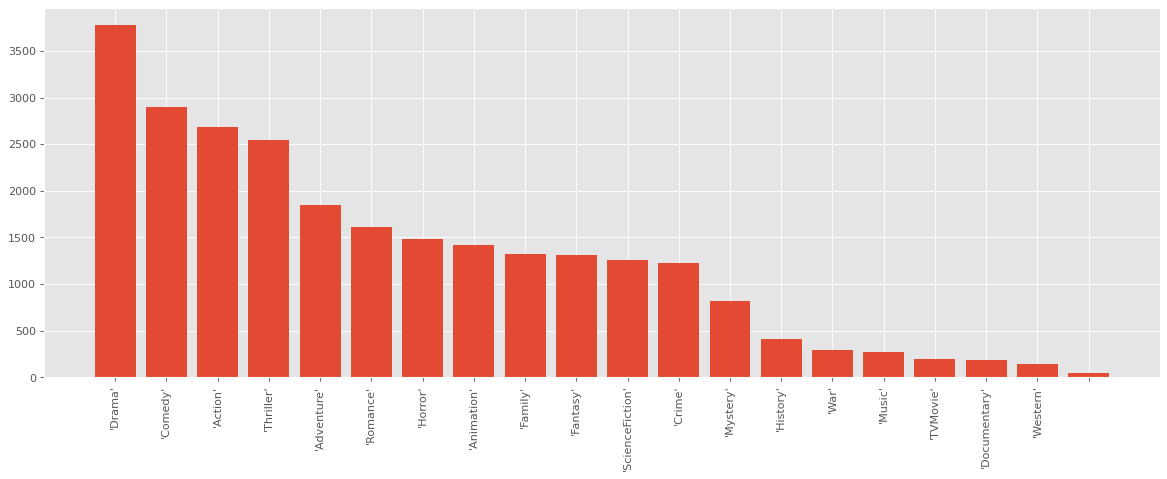

In [ ]:
import matplotlib.pyplot as plt
from collections import Counter, OrderedDict

plt.style.use('ggplot')

def plot_generos(df=filmes, num=50):
    generos = []
    for i, rows in df.iterrows():
      generos+=rows['genres'].split(',')

    counter_object = Counter(generos)
    srt_dct = dict(sorted(counter_object.items(), key=lambda item: item[1], reverse=True))
    keys = list(srt_dct.keys())[:num]
    num_values = list(srt_dct.values())[:num]

    plt.figure(figsize=(18, 6), dpi=80)
    plt.bar(keys, num_values)
    plt.xticks(rotation=90)
    plt.show()

plot_generos(filmes)

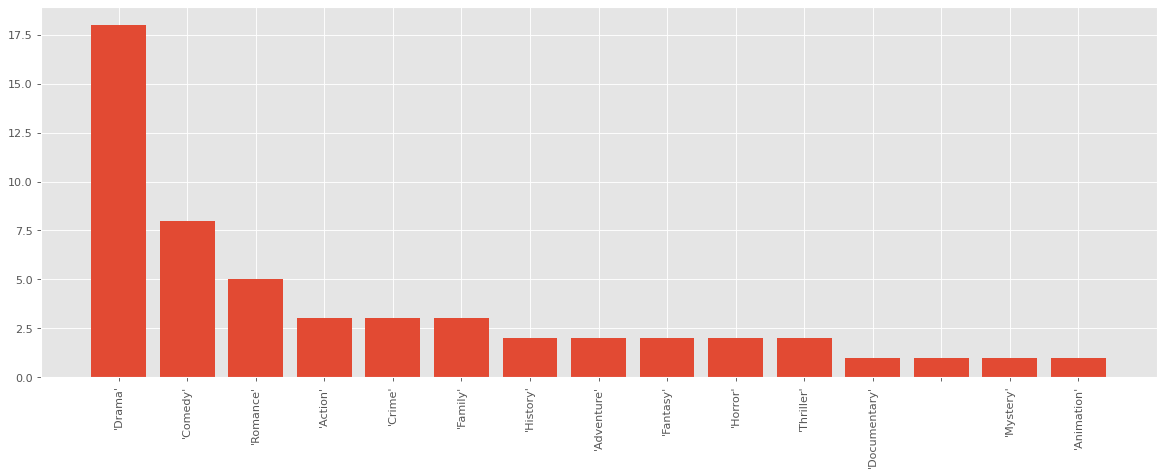

In [ ]:
plot_generos(filmes_pt)

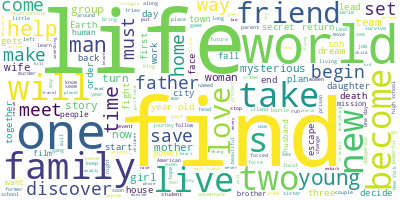

In [ ]:
# Importar a biblioteca wordcloud
from wordcloud import WordCloud

# Juntar toda coluna 'overview'
long_string = ','.join(list(filmes['overview'].values))

# Criar o objeto WordCloud
wordcloud = WordCloud(background_color="white", max_words=5000, contour_width=3, contour_color='steelblue')

# Gerar núvem de palavras
wordcloud.generate(long_string)

# Mostrar núvem de palavras
wordcloud.to_image()

## 4. Modelagem de dados

In [ ]:
# Importar biblioteca de expressão regular
import re

# Remover pontuação
filmes['overview'] = filmes['overview'].map(lambda x: re.sub('[,\.!?]', '', x))

# Converter para caixa baixa
filmes['overview'] = filmes['overview'].map(lambda x: x.lower())

# Mostrar 5 amostras aleatórias
filmes['overview'].sample(5)

5953    when recently single steven moves into his new...
2892    a woman learns about the death of her orthodox...
8630    invited to a wealthy client's mansion time-tra...
8008    the story of humankind's last stand against a ...
1562    marty and doc are at it again in this wacky se...
Name: overview, dtype: object

In [ ]:
from sklearn.feature_extraction.text import TfidfVectorizer

corpus = filmes['overview']
vectorizer = TfidfVectorizer()
X = vectorizer.fit_transform(corpus)

In [ ]:
from sklearn.cluster import KMeans

kmeans = KMeans(n_clusters= 7, init='k-means++', random_state=0)
kmeans.fit(X)

/usr/local/lib/python3.10/dist-packages/sklearn/cluster/_kmeans.py:870: FutureWarning:

The default value of `n_init` will change from 10 to 'auto' in 1.4. Set the value of `n_init` explicitly to suppress the warning



KMeans(n_clusters=7, random_state=0)

In [ ]:
y_kmeans = kmeans.fit_predict(X)

In [ ]:
filmes['group'] = y_kmeans

filmes.head(5)

,id,title,release_date,genres,original_language,popularity,overview,group
0,758323,The Pope's Exorcist,2023-04-05,"'Horror','Mystery','Thriller'",English,5089.969,father gabriele amorth chief exorcist of the v...,6
1,640146,Ant-Man and the Wasp: Quantumania,2023-02-15,"'Action','Adventure','ScienceFiction'",English,4665.438,super-hero partners scott lang and hope van dy...,6
2,502356,The Super Mario Bros. Movie,2023-04-05,"'Animation','Adventure','Family','Fantasy','Co...",English,3935.550,while working underground to fix a water main ...,6
3,868759,Ghosted,2023-04-18,"'Action','Comedy','Romance'",English,2791.532,salt-of-the-earth cole falls head over heels f...,5
4,594767,Shazam! Fury of the Gods,2023-03-15,"'Action','Comedy','Fantasy','Adventure'",English,2702.593,billy batson and his foster siblings who trans...,5


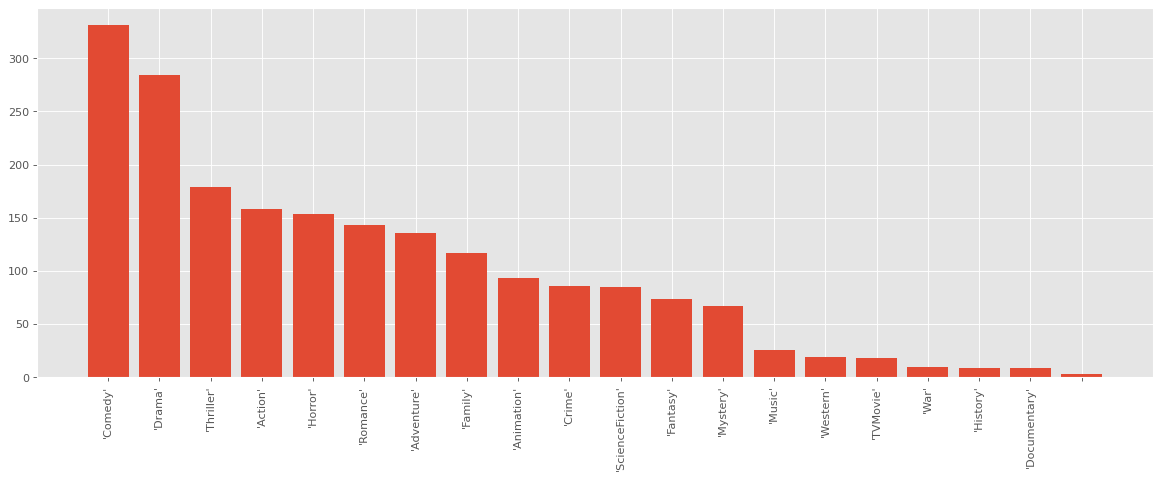

In [ ]:
plot_generos(filmes[ filmes['group'] == 0])

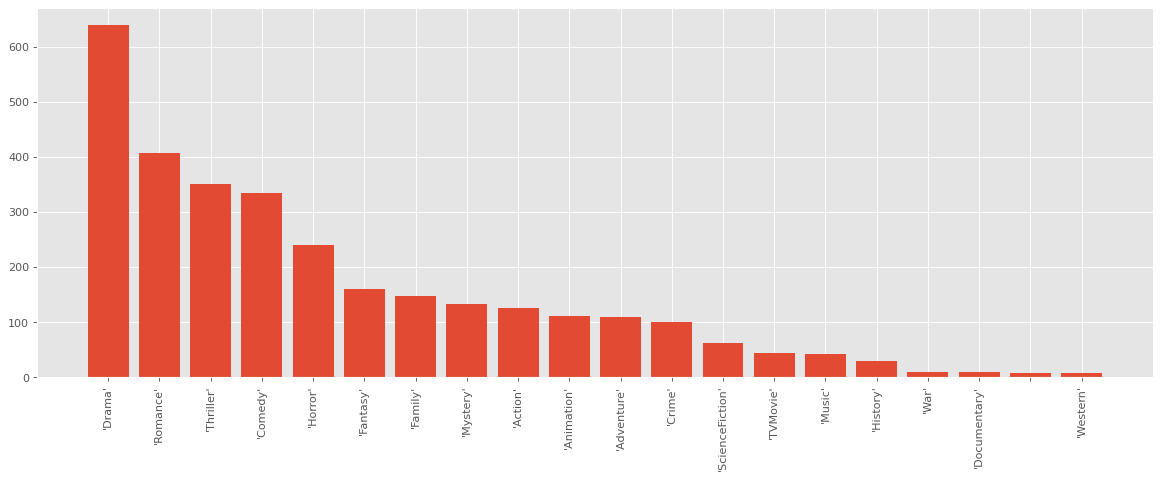

In [ ]:
plot_generos(filmes[ filmes['group'] == 1])

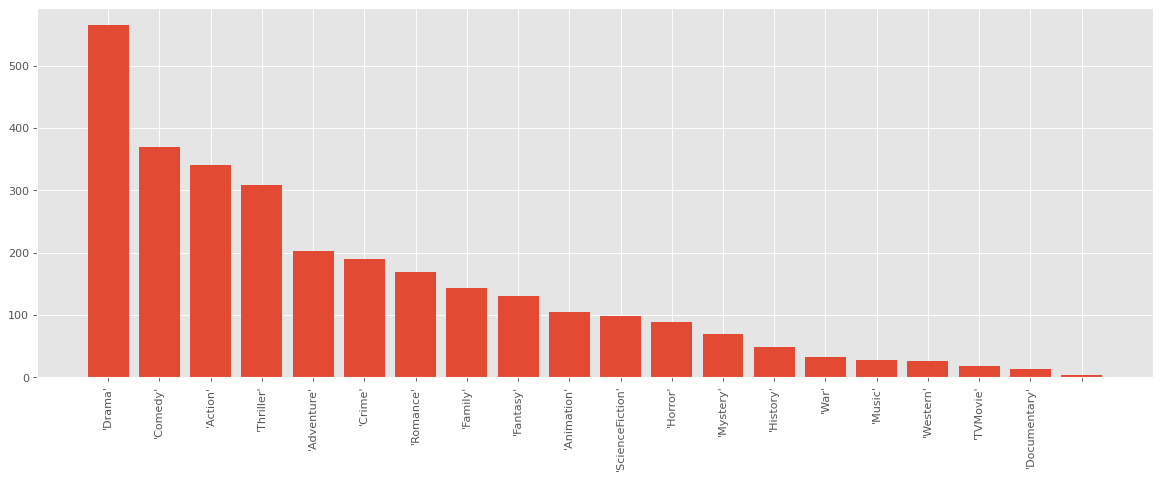

In [ ]:
plot_generos(filmes[ filmes['group'] == 2])

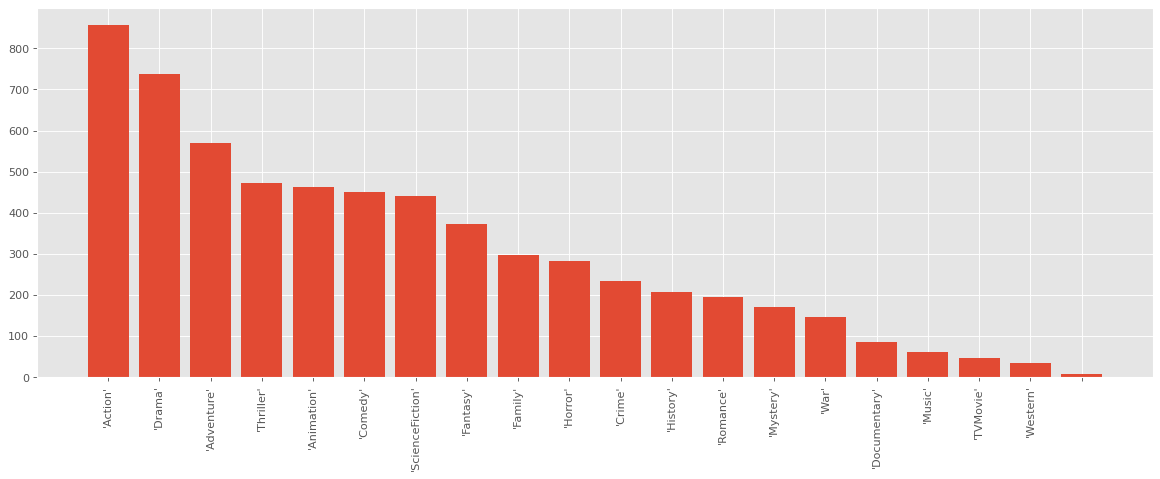

In [ ]:
plot_generos(filmes[ filmes['group'] == 3])

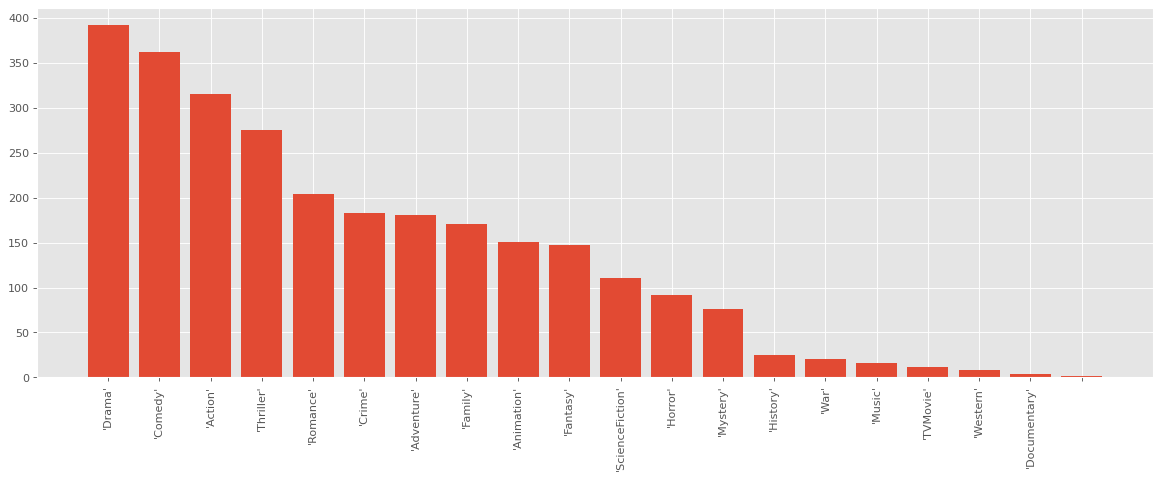

In [ ]:
plot_generos(filmes[ filmes['group'] == 4])

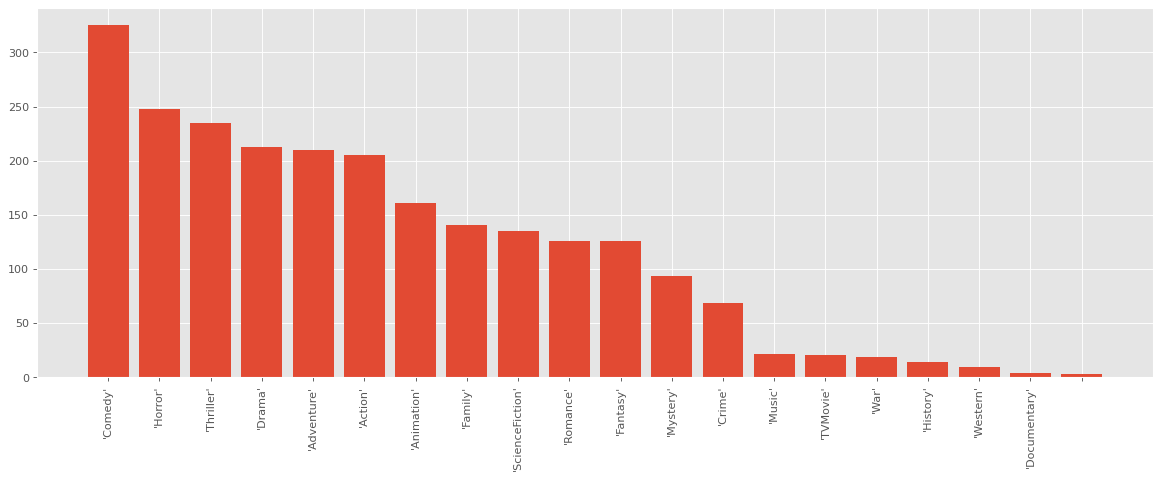

In [ ]:
plot_generos(filmes[ filmes['group'] == 5])

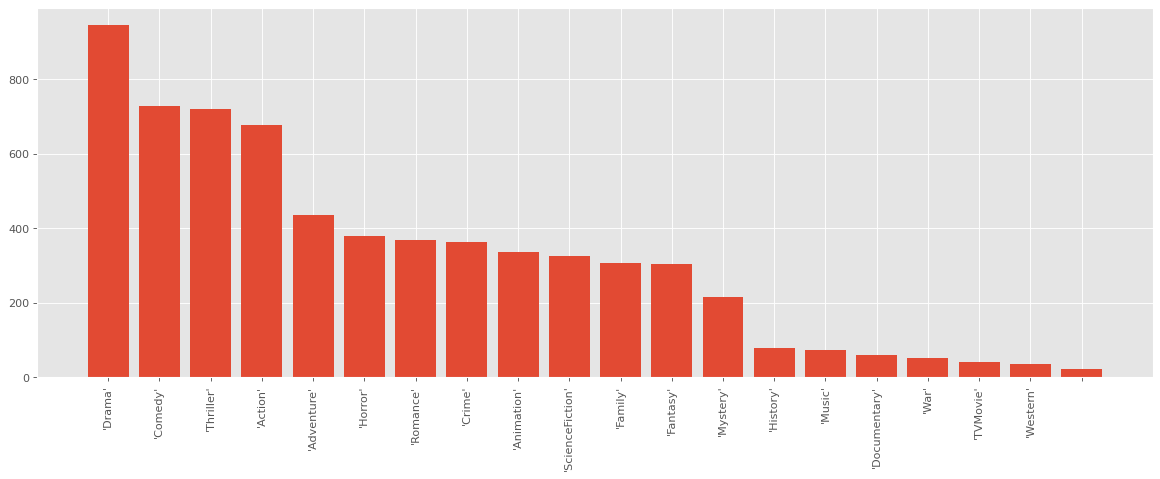

In [ ]:
plot_generos(filmes[ filmes['group'] == 6])